# 微调前后 Encoder 特征空间对比（t-SNE）

## 先说一个前提

`fineTuning.py` **不会保存微调后的模型** —— 整个文件里没有一个 `torch.save`，
它只往 `results/close/results-*.txt` 追加准确率。`SaveModel/` 下现存的
`D1-Undefence-Ori/model_epoch_200.pth` 等，都只是**预训练**阶段的产物。

所以「微调后的模型」目前并不存在于磁盘上。本 notebook 的做法是：

| 对比项 | 来源 |
|---|---|
| **微调前** | `SaveModel/D1-Undefence-Ori/model_epoch_200.pth`（预训练 encoder，直接加载） |
| **微调后** | 在本 notebook 内跑一次**与 `fineTuning.py` 等价**的微调得到（不落盘） |

微调超参与 `fineTuning.py` 保持一致：`lr=1e-4`、`batch_size=16`、`epochs=41`、
encoder 与线性分类头一起训。唯一差别是脚本里 `num_runs=5` 取均值，这里只跑 1 个 run
（画 t-SNE 只需要一个具体的模型）。

> 想让微调后的 encoder 以后能直接复用，需要在 `fineTuning.py` 里补一句 `torch.save`。

**被测数据**：目标域 `*-FineTune.npz` 里的 `X_tune_test`（100 个网站 × 50 条 = 5000 条），
按网站序号上色。两个 panel 用的是**完全相同**的一批 trace。


## 一、配置

改下面这几个常量就能换实验：`TARGET_DOMAIN`（`D2/D3/D4/D5-Undefence` 是 Scenario#1，
`D6-Undefence` 是 Scenario#2）、`N_SHOT`、`PRETRAINED`。


In [1]:
import os, sys, time
import numpy as np
import torch
import torch.nn as nn
import yaml
from torch.utils.data import DataLoader, Dataset
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# 保证工作目录是仓库根（config.yaml / SaveModel / SaveData 都在这里）
if not os.path.exists("config.yaml"):
    for cand in ("..", os.path.join("..", "..")):
        if os.path.exists(os.path.join(cand, "config.yaml")):
            os.chdir(cand)
            break
sys.path.insert(0, os.path.abspath("."))
from models.resnet_base_network import ResNet18
print("cwd =", os.getcwd())

# ---------- 配色（参考调色板）。WSL 里没有中文字体，图内文字一律用英文 ----------
SURFACE, INK, INK2, MUTED, GRIDC = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
C_BEFORE, C_AFTER = "#2a78d6", "#eb6834"      # 分类色槽 1 / 2（全配对已校验）
C_HL3, C_OTHER = "#1baf7a", "#c3c2b7"         # 槽 3 / 灰
# 顺序色标：最浅一档取到 >= 2:1 对比度，避免点融进画布
CMAP_SITE = LinearSegmentedColormap.from_list(
    "swallow_blue", ["#86b6ef", "#5598e7", "#2a78d6", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK2, "axes.edgecolor": "#c3c2b7",
    "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": GRIDC, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "figure.dpi": 110,
})

# ---------------- 实验配置 ----------------
CFG    = yaml.load(open("config.yaml"), Loader=yaml.FullLoader)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

PRETRAINED    = "D1-Undefence-Ori"   # SaveModel/ 下的目录名（预训练模型）
TARGET_DOMAIN = "D2-Undefence"       # 微调目标域
N_SHOT        = 20                   # 每类 N 条（fineTuning.py 用 5/10/15/20）
NUM_EPOCHS    = 41                   # 与 fineTuning.py 一致
BATCH_SIZE    = 16
LR            = 1e-4
SEED          = 0

MAX_PER_SITE  = 20    # t-SNE 每类最多取多少条测试样本（100 类 x 50 条全画会糊成一团）
N_PCA         = 50    # t-SNE 之前先降到的维度
PERPLEXITY    = 30
TSNE_SEED     = 42
HIGHLIGHT     = [0, 1, 2]   # 第二个图里高亮的 3 个网站序号

print("torch", torch.__version__, "| device:", DEVICE,
      "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")
print(f"对比: 预训练 {PRETRAINED}  --(微调 on {TARGET_DOMAIN}, N={N_SHOT})-->  微调后")

cwd = /mnt/d/workspace/Swallow
torch 2.4.1+cu121 | device: cuda | NVIDIA GeForce RTX 2060
对比: 预训练 D1-Undefence-Ori  --(微调 on D2-Undefence, N=20)-->  微调后


## 二、数据、模型与微调函数

三个函数都是照着 `fineTuning.py` 复刻的：

- `build_pretrained_encoder()` —— `ResNet18` 载入 `online_network_state_dict`，再
  `nn.Sequential(*list(children())[:-1])` 去掉 projection head，输出 **512 维**。
- `sample_n_per_class()` —— 复刻 `sample_traces()`。
- `finetune_encoder()` —— 复刻单次 run：encoder + 一个 `nn.Linear(512, 100)` 一起用
  Adam / CrossEntropy 训 41 个 epoch。


In [2]:
class TraceData(Dataset):
    """与 fineTuning.py 里的 Data 一致。"""
    def __init__(self, x, y):
        self.x, self.y = x, y
    def __getitem__(self, i):
        return self.x[i], self.y[i]
    def __len__(self):
        return len(self.x)


def load_target(domain):
    d = np.load(CFG["path"]["finetune_data"] + f"{domain}-FineTune.npz")
    return d["X_tune_train"], d["Y_tune_train"], d["X_tune_test"], d["Y_tune_test"]


def build_pretrained_encoder(model_name=PRETRAINED):
    """复刻 fineTuning.py 的加载方式：载入 online_network_state_dict -> 去掉 projection head。"""
    net = ResNet18(**CFG["network"])
    sd = torch.load(f"{CFG['path']['model_path']}{model_name}/model_epoch_200.pth",
                    map_location="cpu")
    net.load_state_dict(sd["online_network_state_dict"])
    return nn.Sequential(*list(net.children())[:-1])


@torch.no_grad()
def extract_features(encoder, X, batch=512):
    """X: (n, 2, 1000) int -> (n, 512) float"""
    encoder.eval()
    outs = []
    for i in range(0, len(X), batch):
        xb = torch.as_tensor(np.asarray(X[i:i + batch])).float().to(DEVICE)
        xb = xb.reshape(xb.shape[0], 1, xb.shape[1], xb.shape[2])
        outs.append(encoder(xb).view(xb.size(0), -1).cpu().numpy())
    return np.concatenate(outs, 0)


def sample_n_per_class(X, y, n, rng):
    """复刻 fineTuning.py 的 sample_traces。"""
    idx = []
    for c in np.unique(y):
        ci = np.where(y == c)[0]
        idx.extend(rng.choice(ci, min(n, len(ci)), replace=False))
    idx = np.array(idx)
    rng.shuffle(idx)
    return X[idx], y[idx]


def finetune_encoder(X_shot, y_shot, epochs=NUM_EPOCHS, seed=SEED, log_every=5):
    """等价于 fineTuning.py 里的单次 run，返回微调后的 encoder 和 loss 曲线。"""
    torch.manual_seed(seed); np.random.seed(seed)
    encoder = build_pretrained_encoder().to(DEVICE)
    head = nn.Linear(512, len(np.unique(y_shot))).to(DEVICE)
    opt = torch.optim.Adam(list(encoder.parameters()) + list(head.parameters()), lr=LR)
    crit = nn.CrossEntropyLoss()
    loader = DataLoader(TraceData(X_shot, y_shot.astype(np.int64)),
                        batch_size=BATCH_SIZE, shuffle=True, drop_last=True)

    encoder.train(); head.train()
    hist = []
    for ep in range(epochs):
        tot = 0.0
        for xb, yb in loader:
            xb = xb.float().to(DEVICE).reshape(xb.shape[0], 1, xb.shape[1], xb.shape[2])
            yb = yb.to(DEVICE)
            f = encoder(xb).view(xb.size(0), -1)
            loss = crit(head(f), yb)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item()
        hist.append(tot / max(len(loader), 1))
        if ep % log_every == 0 or ep == epochs - 1:
            print(f"  epoch {ep:>3}/{epochs - 1}   train loss {hist[-1]:.4f}")
    encoder.eval()
    return encoder, hist


def l2n(F):
    return F / (np.linalg.norm(F, axis=1, keepdims=True) + 1e-12)


def embed_tsne(F, seed=TSNE_SEED):
    """L2 归一化 -> PCA -> t-SNE。前后两个 encoder 走完全相同的流程，才可比。"""
    Z = PCA(n_components=N_PCA, random_state=seed).fit_transform(l2n(F))
    return TSNE(n_components=2, perplexity=PERPLEXITY, init="pca",
                learning_rate="auto", random_state=seed).fit_transform(Z)

## 三、跑一遍：微调前特征 → 微调 → 微调后特征

`N=20 shots/网站`、41 个 epoch，在 RTX 2060 上大致几分钟。
结果存在字典 `R` 里并有缓存保护 —— 重复执行这个 cell 不会重新训练（要重跑先 `del R`）。


In [3]:
t0 = time.time()
if "R" not in globals():
    X_tr, y_tr, X_te, y_te = load_target(TARGET_DOMAIN)
    cnt = np.bincount(y_te)
    print(f"{TARGET_DOMAIN}: train {X_tr.shape}  test {X_te.shape}  "
          f"{len(cnt)} 个网站，每类 {cnt.min()} 条")

    # --- t-SNE 用的测试集子集（每个网站抽 MAX_PER_SITE 条，两次抽取固定种子）---
    rng = np.random.default_rng(123)
    sel = []
    for c in np.unique(y_te):
        ci = np.where(y_te == c)[0]
        sel.extend(rng.choice(ci, min(MAX_PER_SITE, len(ci)), replace=False))
    sel = np.sort(np.array(sel))
    X_vis, y_vis = X_te[sel], y_te[sel]
    print(f"t-SNE 子集: {X_vis.shape[0]} 条 ({MAX_PER_SITE}/网站)")

    # --- N-shot 微调样本（与 fineTuning.py 同样的采样方式）---
    X_shot, y_shot = sample_n_per_class(X_tr, y_tr, N_SHOT, np.random.default_rng(SEED))
    print(f"N-shot 训练集: {X_shot.shape[0]} 条 ({N_SHOT}/网站)")

    # --- 微调前 ---
    enc_pre = build_pretrained_encoder().to(DEVICE)
    F_pre_vis  = extract_features(enc_pre, X_vis)
    F_pre_shot = extract_features(enc_pre, X_shot)
    F_pre_te   = extract_features(enc_pre, X_te)
    print("微调前特征提取完成:", F_pre_vis.shape)

    # --- 微调 ---
    print(f"\n开始微调 {PRETRAINED} -> {TARGET_DOMAIN} "
          f"(N={N_SHOT}, {NUM_EPOCHS} epochs, batch={BATCH_SIZE}, lr={LR}) ...")
    enc_post, loss_hist = finetune_encoder(X_shot, y_shot)
    print(f"微调结束，用时 {time.time() - t0:.1f}s")

    # --- 微调后 ---
    F_post_vis  = extract_features(enc_post, X_vis)
    F_post_shot = extract_features(enc_post, X_shot)
    F_post_te   = extract_features(enc_post, X_te)

    R = dict(X_vis=X_vis, y_vis=y_vis, X_te=X_te, y_te=y_te,
             X_shot=X_shot, y_shot=y_shot,
             F_pre_vis=F_pre_vis, F_post_vis=F_post_vis,
             F_pre_shot=F_pre_shot, F_post_shot=F_post_shot,
             F_pre_te=F_pre_te, F_post_te=F_post_te,
             loss_hist=loss_hist)
    print("\n全部完成。")
else:
    print("已有缓存 R，跳过训练。要重新训练请先执行:  del R")

D2-Undefence: train (5000, 2, 1000)  test (5000, 2, 1000)  100 个网站，每类 50 条
t-SNE 子集: 2000 条 (20/网站)
N-shot 训练集: 2000 条 (20/网站)


/mnt/d/workspace/WF-HAP/.venv/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/mnt/d/workspace/WF-HAP/.venv/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
/tmp/ipykernel_17668/1982267669.py:19: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be fl

微调前特征提取完成: (2000, 512)

开始微调 D1-Undefence-Ori -> D2-Undefence (N=20, 41 epochs, batch=16, lr=0.0001) ...
  epoch   0/40   train loss 4.5240
  epoch   5/40   train loss 2.2409
  epoch  10/40   train loss 0.4432
  epoch  15/40   train loss 0.1351
  epoch  20/40   train loss 0.0549
  epoch  25/40   train loss 0.0868
  epoch  30/40   train loss 0.0094
  epoch  35/40   train loss 0.0060
  epoch  40/40   train loss 0.0040
微调结束，用时 133.8s

全部完成。


## 四、定量指标（t-SNE 之外的证据）

t-SNE 会**夸大**簇间距离，只靠看图容易得出过于乐观的结论，所以同时算四个数：

| 指标 | 含义 |
|---|---|
| **Linear probe acc.** | 用**同一批 N-shot 样本**训一个逻辑回归，在完整 5000 条测试集上测 —— 和论文的 few-shot 协议一致 |
| **kNN (k=5) acc.** | 特征空间里最近邻的标签一致率，不训练分类器 |
| **Silhouette** | 类内紧致度 vs 类间分离度（余弦距离，-1~1，越大越好） |
| **Intra / inter dist.** | 类内平均距离 / 类间平均距离，越小于 1 越好 |

前两个指标用完整测试集；后两个在 t-SNE 用的 2000 条子集上算。


In [4]:
def eval_encoder(F_shot, y_shot, F_te, y_te):
    """线性探测 + kNN，都只用那 N 条/网站的样本训练。"""
    sc = StandardScaler().fit(F_shot)
    A, B = sc.transform(F_shot), sc.transform(F_te)
    lin = LogisticRegression(max_iter=1000).fit(A, y_shot)
    acc_lin = 100 * lin.score(B, y_te)
    knn = KNeighborsClassifier(n_neighbors=5).fit(l2n(F_shot), y_shot)
    acc_knn = 100 * knn.score(l2n(F_te), y_te)
    return acc_lin, acc_knn


def sep_metrics(F, y):
    """类分离度：silhouette + 类内/类间平均距离比（都在 L2 归一化特征上算）。"""
    A = l2n(F)
    uniq = np.unique(y)
    cents = np.stack([A[y == c].mean(0) for c in uniq])
    cents /= np.linalg.norm(cents, axis=1, keepdims=True) + 1e-12
    intra = float(np.mean([np.linalg.norm(A[y == c] - cents[i], axis=1).mean()
                           for i, c in enumerate(uniq)]))
    D = np.linalg.norm(cents[:, None, :] - cents[None, :, :], axis=-1)
    inter = float(D[~np.eye(len(uniq), dtype=bool)].mean())
    return silhouette_score(A, y, metric="cosine"), intra / inter


rows = []
for name, k_pre, k_post in [("微调前", "pre", "pre"), ("微调后", "post", "post")]:
    acc_lin, acc_knn = eval_encoder(R[f"F_{k_pre}_shot"], R["y_shot"],
                                    R[f"F_{k_post}_te"], R["y_te"])
    sil, ratio = sep_metrics(R[f"F_{k_pre}_vis"], R["y_vis"])
    rows.append(dict(name=name, acc_lin=acc_lin, acc_knn=acc_knn, sil=sil, ratio=ratio))

print(f"目标域 {TARGET_DOMAIN} | N={N_SHOT} shots/网站 | 测试集 {len(R['y_te'])} 条\n")
print(f"{'':<8}{'Linear probe':>14}{'kNN(k=5)':>12}{'Silhouette':>13}{'Intra/Inter':>14}")
for r in rows:
    print(f"{r['name']:<8}{r['acc_lin']:>13.2f}%{r['acc_knn']:>11.2f}%"
          f"{r['sil']:>13.3f}{r['ratio']:>14.3f}")
print("\n注：probe / kNN 只用 N-shot 样本训练，测试集是完整 5000 条；")
print("    Silhouette 与 Intra/Inter 在 t-SNE 用的子集、L2 归一化特征上算。")

目标域 D2-Undefence | N=20 shots/网站 | 测试集 5000 条

          Linear probe    kNN(k=5)   Silhouette   Intra/Inter
微调前             89.24%      84.68%        0.198         0.608
微调后             94.22%      94.10%        0.754         0.212

注：probe / kNN 只用 N-shot 样本训练，测试集是完整 5000 条；
    Silhouette 与 Intra/Inter 在 t-SNE 用的子集、L2 归一化特征上算。


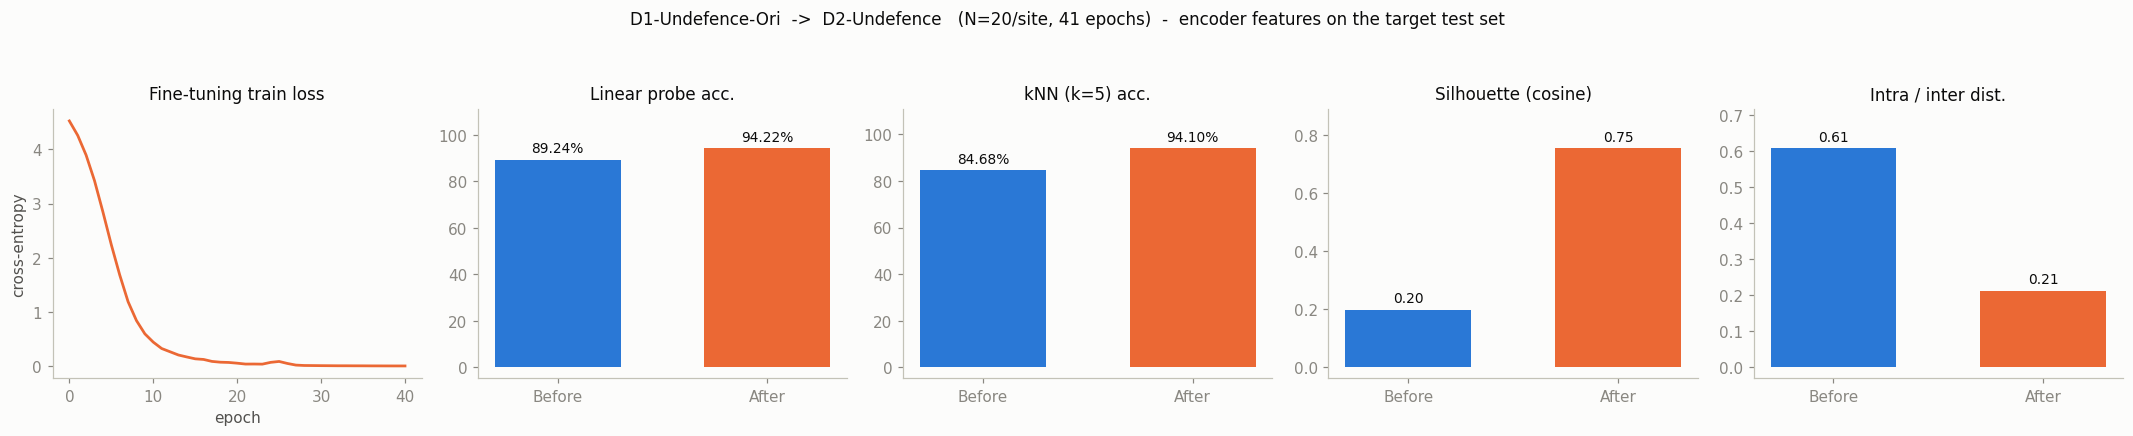

In [5]:
fig, axes = plt.subplots(1, 5, figsize=(19.5, 3.7))

# 1) 微调 loss 曲线，确认训练确实收敛了
ax = axes[0]
ax.plot(range(len(R["loss_hist"])), R["loss_hist"], color=C_AFTER, lw=1.8)
ax.set_title("Fine-tuning train loss")
ax.set_xlabel("epoch")
ax.set_ylabel("cross-entropy")

# 2~5) 四个指标的前后对比。量纲各不相同，所以用小多图而不是堆叠柱状图
specs = [("Linear probe acc.", "acc_lin", "%"),
         ("kNN (k=5) acc.",    "acc_knn", "%"),
         ("Silhouette (cosine)", "sil",   ""),
         ("Intra / inter dist.", "ratio", "")]
for ax, (title, key, unit) in zip(axes[1:], specs):
    vals = [r[key] for r in rows]
    bars = ax.bar([0, 1], vals, width=0.6,
                  color=[C_BEFORE, C_AFTER], zorder=3)
    span = max(vals) - min(0, min(vals))
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + span * 0.02,
                format(v, ".2f") + unit, ha="center", va="bottom",
                color=INK, fontsize=9)
    ax.set_title(title)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Before", "After"])
    ax.set_ylim(min(0, min(vals)) - span * 0.05, max(vals) + span * 0.18)
    ax.grid(axis="x", visible=False)

fig.suptitle(f"{PRETRAINED}  ->  {TARGET_DOMAIN}   "
             f"(N={N_SHOT}/site, {NUM_EPOCHS} epochs)  -  encoder features on the target test set",
             y=1.06, fontsize=11)
fig.tight_layout()
plt.show()

## 五、t-SNE 前后对比

两个 panel 喂的是**同一批 trace**，只有 encoder 不同。

⚠️ 两个 panel 的 t-SNE 是**各自独立优化**的，所以**跨 panel 比坐标没有意义**，
只能比每个 panel 内部「同类点是否抱团」。这也是为什么要配上面那张指标图。

100 个网站没法用离散配色（分类色板在散点这种全配对场景只保证前 3 个色槽），
所以这里用**连续色标**表示网站序号 —— 颜色编码的是「序号」而不是「身份」，
用来判断整体结构，具体是哪一类不去分辨。


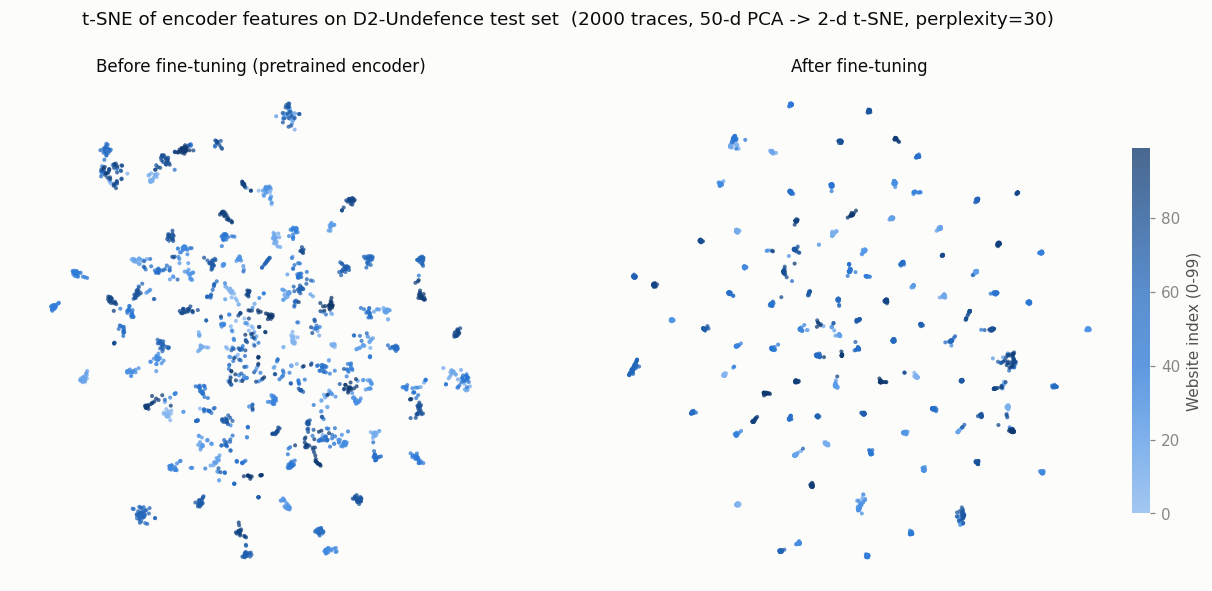

In [6]:
Z_pre  = embed_tsne(R["F_pre_vis"])
Z_post = embed_tsne(R["F_post_vis"])

fig, axes = plt.subplots(1, 2, figsize=(13.5, 6.0))
for ax, Z, title in [(axes[0], Z_pre,  "Before fine-tuning (pretrained encoder)"),
                     (axes[1], Z_post, "After fine-tuning")]:
    sc = ax.scatter(Z[:, 0], Z[:, 1], c=R["y_vis"], cmap=CMAP_SITE, vmin=0, vmax=99,
                    s=7, alpha=0.75, linewidths=0)
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.set_aspect("equal", adjustable="datalim")
    ax.set_box_aspect(1)          # 两个 panel 同样大小，只比内部结构
    for s in ax.spines.values():
        s.set_visible(False)

cb = fig.colorbar(sc, ax=axes.tolist(), fraction=0.026, pad=0.02, shrink=0.72)
cb.set_label("Website index (0-99)")
cb.outline.set_visible(False)

fig.suptitle(f"t-SNE of encoder features on {TARGET_DOMAIN} test set  "
             f"({len(R['y_vis'])} traces, {N_PCA}-d PCA -> 2-d t-SNE, perplexity={PERPLEXITY})",
             y=0.98)
plt.show()

### 再多看三个具体网站

上面 100 类挤在一起看不出个体。这里只挑 3 个网站上色，其余一律淡灰
（色板规则：超过 3 个分类色槽就不再保证全配对可分辨，剩下的折叠成「其他」），
并把类名直接标在类心旁 —— 不靠颜色单独承载信息。


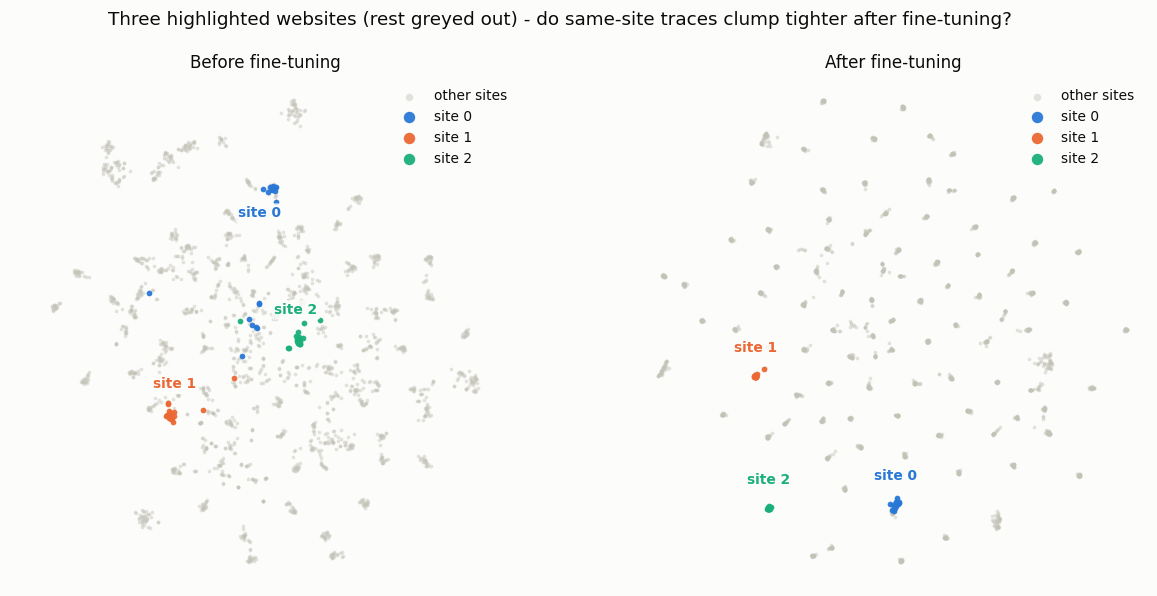

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 6.0))
cols = [C_BEFORE, C_AFTER, C_HL3]
other = ~np.isin(R["y_vis"], HIGHLIGHT)

for ax, Z, title in [(axes[0], Z_pre,  "Before fine-tuning"),
                     (axes[1], Z_post, "After fine-tuning")]:
    ax.scatter(Z[other, 0], Z[other, 1], c=C_OTHER, s=6, alpha=0.45,
               linewidths=0, label="other sites", zorder=2)
    for k, site in enumerate(HIGHLIGHT):
        m = R["y_vis"] == site
        ax.scatter(Z[m, 0], Z[m, 1], c=cols[k], s=14, alpha=0.95,
                   linewidths=0, label=f"site {site}", zorder=3)
        cx, cy = Z[m, 0].mean(), Z[m, 1].mean()
        ax.annotate(f"site {site}", (cx, cy), textcoords="offset points", xytext=(0, 16),
                    ha="center", fontsize=9, color=cols[k], weight="bold", zorder=4,
                    bbox=dict(boxstyle="round,pad=0.2", fc=SURFACE, ec="none", alpha=0.85))
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.set_aspect("equal", adjustable="datalim")
    ax.set_box_aspect(1)          # 两个 panel 同样大小
    for s in ax.spines.values():
        s.set_visible(False)
    ax.legend(loc="upper right", frameon=False, fontsize=9, markerscale=2)

fig.suptitle("Three highlighted websites (rest greyed out) - "
             "do same-site traces clump tighter after fine-tuning?", y=0.98)
plt.show()

## 六、自动小结 + 需要注意的地方

In [8]:
b, a = rows[0], rows[1]
def _show(label, key, unit="", fmt=".2f"):
    print(f"  {label:<22} {format(b[key], fmt) + unit:>10}  ->  "
          f"{format(a[key], fmt) + unit:>10}   ({format(a[key] - b[key], '+' + fmt) + unit})")

print(f"{PRETRAINED} -> {TARGET_DOMAIN}  (N={N_SHOT}, {NUM_EPOCHS} epochs)\n")
_show("Linear probe acc.", "acc_lin", "%")
_show("kNN (k=5) acc.",    "acc_knn", "%")
_show("Silhouette",        "sil",     "", ".3f")
_show("Intra / inter dist.", "ratio", "", ".3f")

print()
print(f"  silhouette {'上升' if a['sil'] > b['sil'] else '下降'}"
      f"，类内/类间距离比 {'下降' if a['ratio'] < b['ratio'] else '上升'}"
      f" -> 微调后特征{'更容易' if a['sil'] > b['sil'] and a['ratio'] < b['ratio'] else '未见得更容易'}按网站聚开")

D1-Undefence-Ori -> D2-Undefence  (N=20, 41 epochs)

  Linear probe acc.          89.24%  ->      94.22%   (+4.98%)
  kNN (k=5) acc.             84.68%  ->      94.10%   (+9.42%)
  Silhouette                  0.198  ->       0.754   (+0.556)
  Intra / inter dist.         0.608  ->       0.212   (-0.396)

  silhouette 上升，类内/类间距离比 下降 -> 微调后特征更容易按网站聚开


### 这些数字不能说明什么

1. **「微调后」这个 encoder 在这 N 条/网站的样本上训过。**
   线性探测精度高是应该的 —— 它衡量的是「特征是否线性可分」，不是泛化能力。
   真正要跟论文表格对，得跑完整 `fineTuning.py`（4 个 N × 5 个 run 取均值）。
2. **只跑了 1 个 run。** `fineTuning.py` 是 `num_runs=5` 取均值，单次 run 的波动不小。
3. **t-SNE 的簇间距离不可比。** 两个 panel 独立优化，只能读各自的内部结构。
4. **子集是抽稀的。** t-SNE 每类 20 条；如果要看全量，把 `MAX_PER_SITE` 调大（会变慢）。
5. **微调用的是目标域的 5000 条 train 里的 N 条/类**，测试集 5000 条完全没参与训练。

### 想让微调后的模型能存下来

现在 `fineTuning.py` 训完就把 encoder 丢掉了。在 `finetune` 函数的内层 `for run` 循环末尾
（`accuracies.append(best_acc)` 之前）加一句即可：

```python
out_dir = f"SaveModel/{model_name}-Finetune-{defence_name}"
os.makedirs(out_dir, exist_ok=True)
torch.save({"encoder_state_dict": encoder.state_dict(),
            "logreg_state_dict": logreg.state_dict(),
            "N_shot": N, "run": run, "test_acc": best_acc},
           f"{out_dir}/N{N}_run{run}.pth")
```

存下来之后，这个 notebook 里把 `finetune_encoder(...)` 换成 `torch.load(...)` 就能直接比对。
